# HVSR-style site response of a dipping soft layer from simulated ambient noise

**Question.** Single-station HVSR is used to map sediment thickness: measure the resonance $f_0$ and convert it with $H = V_{s1}/(4f_0)$. That formula is 1D. How well does it work when the soft layer sits on a **dipping** rock interface, and how does it depend on the **impedance contrast**?

**Method.** A 2D depth slice (x-z) with a soft layer over rock. We solve the SH wave equation $\rho u_{tt} + \rho\sigma u_t = \nabla\cdot(\mu\nabla u)$ (free surface on top, sponges elsewhere, soft-layer damping with $Q = 20$ at the local resonance) by finite differences (`hvsr.py`, verified in `hvsr_verification.ipynb`). 60 point sources in the rock fire independent random noise at the same time, so waves arrive at the surface from all incidence angles. 31 receivers along the surface record the horizontal motion $u$.

**Simplification (stated up front).** An SH/scalar model has only one (horizontal, out-of-plane) component, so there is no vertical component to form a true H/V ratio. We use the closely related **site-to-reference spectral ratio**: the surface spectrum over the soft layer divided by the surface spectrum of bare rock under the same noise. For a strong contrast, H/V and this ratio both peak near $f_0$; H/V amplitudes are not reproduced.

In [1]:
import time, numpy as np, matplotlib.pyplot as plt
import hvsr as H
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
GRID = H.default_grid(5.0)        # dx = 5 m: f0 picks agree with dx = 2.5 m within a few % (checked below)
T = 120.0                         # seconds of noise per run
runs = {}
def run(**kw):
    key = tuple(sorted(kw.items()))
    if key not in runs:
        runs[key] = H.run_profile(H.Model(**kw), GRID, T=T)
    return runs[key]
m = H.Model()
print(f"default model: Vs1 = {m.vs1:.0f} m/s, rho1 = {m.rho1:.0f}; Vs2 = {m.vs2:.0f} m/s, rho2 = {m.rho2:.0f}; "
      f"impedance contrast {m.contrast:.1f}; H(0) = {m.h0:.0f} m, f0(0) = {m.f0_1d(0):.2f} Hz")

default model: Vs1 = 250 m/s, rho1 = 1800; Vs2 = 1000 m/s, rho2 = 2300; impedance contrast 5.1; H(0) = 30 m, f0(0) = 2.08 Hz


## 1. The noise wavefield
One snapshot of the horizontal motion for a 10° dip. The rock carries long-wavelength noise from all the sources; the soft layer traps and amplifies it.

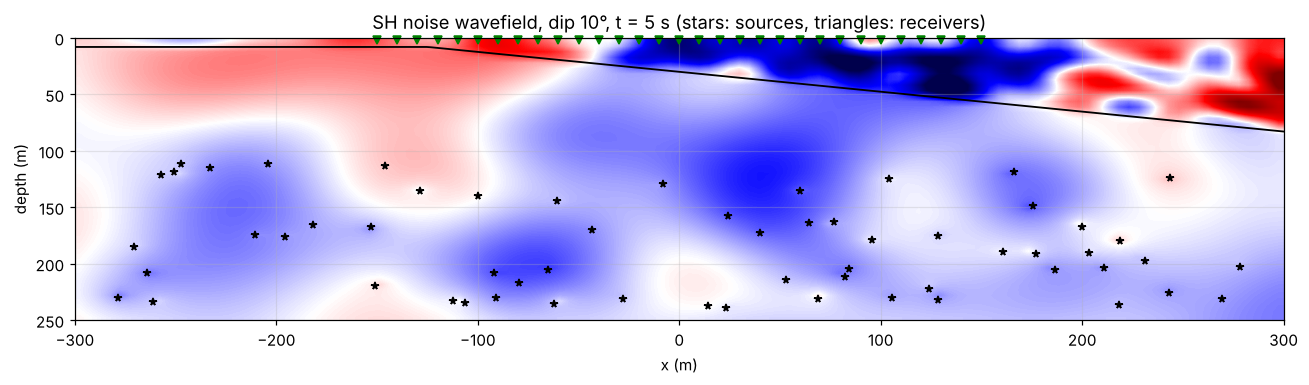

In [2]:
src = H.noise_sources()
snap = H.simulate_noise(H.Model(dip=10.0), GRID, T=6.0, snapshots=[5.0], src=src)
fr = snap["snaps"][5.0]; lim = np.percentile(np.abs(fr), 99.5)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.imshow(fr, extent=[snap["x_snap"][0], snap["x_snap"][-1], snap["z_snap"][-1], snap["z_snap"][0]], cmap="seismic",
          vmin=-lim, vmax=lim, aspect="auto", interpolation="bilinear")
xx = np.linspace(-300, 300, 300)
ax.plot(xx, H.Model(dip=10.0).thickness(xx), "k", lw=1.2)
ax.plot(src[0], src[1], "k*", ms=5); ax.plot(snap["rec_x"], np.full(31, 2.0), "gv", ms=5, clip_on=False)
ax.set(xlabel="x (m)", ylabel="depth (m)", title="SH noise wavefield, dip 10°, t = 5 s (stars: sources, triangles: receivers)")
plt.tight_layout()

## 2. Flat layer: the baseline

f0 picks 2.01-2.08 Hz vs Vs1/4H = 2.08 Hz (error -3.6 to -0.0 %); mean peak ratio 3.75 vs 1D 4.25


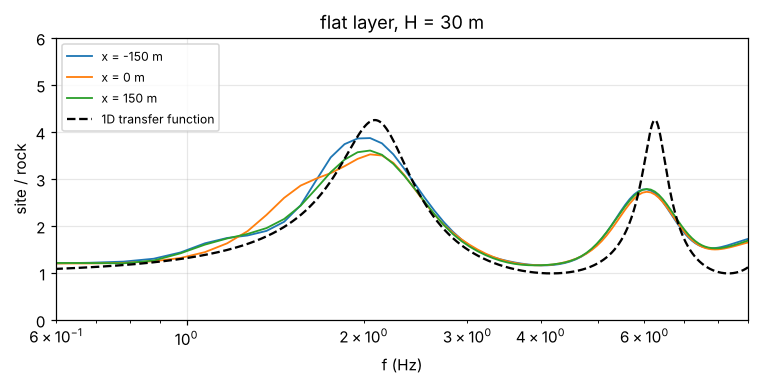

In [3]:
r0 = run(dip=0.0)
ff = np.linspace(0.3, 9, 2000)
fig, ax = plt.subplots(figsize=(7, 3.6))
for j in (0, 15, 30):
    ax.plot(r0["f"], r0["R"][:, j], lw=1.2, label=f"x = {r0['rec_x'][j]:.0f} m")
ax.plot(ff, m.transfer_1d(ff), "k--", label="1D transfer function")
ax.set(xscale="log", xlim=(0.6, 9), ylim=(0, 6), xlabel="f (Hz)", ylabel="site / rock", title="flat layer, H = 30 m"); ax.legend(fontsize=8)
plt.tight_layout()
e = 100 * (r0["f0"] / m.f0_1d(0) - 1)
print(f"f0 picks {r0['f0'].min():.2f}-{r0['f0'].max():.2f} Hz vs Vs1/4H = {m.f0_1d(0):.2f} Hz (error {e.min():+.1f} to {e.max():+.1f} %); "
      f"mean peak ratio {r0['A0'].mean():.2f} vs 1D {m.transfer_1d(ff).max():.2f}")

## 3. Dipping interface
Dips of 0-15°, thickness 30 m under the middle receiver. Top: the spectral ratio along the line (colour) with the 1D prediction $V_{s1}/4H(x)$ (white dashes) and the picks (red). Bottom: the thickness inferred with the 1D formula, $V_{s1}/4f_0$, against the true thickness.

 dip   mean H error   max |H error|   thick side (x>0)   thin side (x<0)
   0°       +2.0 %          3.7 %            +1.3 %            +2.7 %
   5°       -3.7 %          8.6 %            -4.8 %            -2.8 %
  10°      -11.4 %         23.0 %           -15.3 %            -7.7 %
  15°      -15.4 %         34.8 %           -25.3 %            -6.1 %


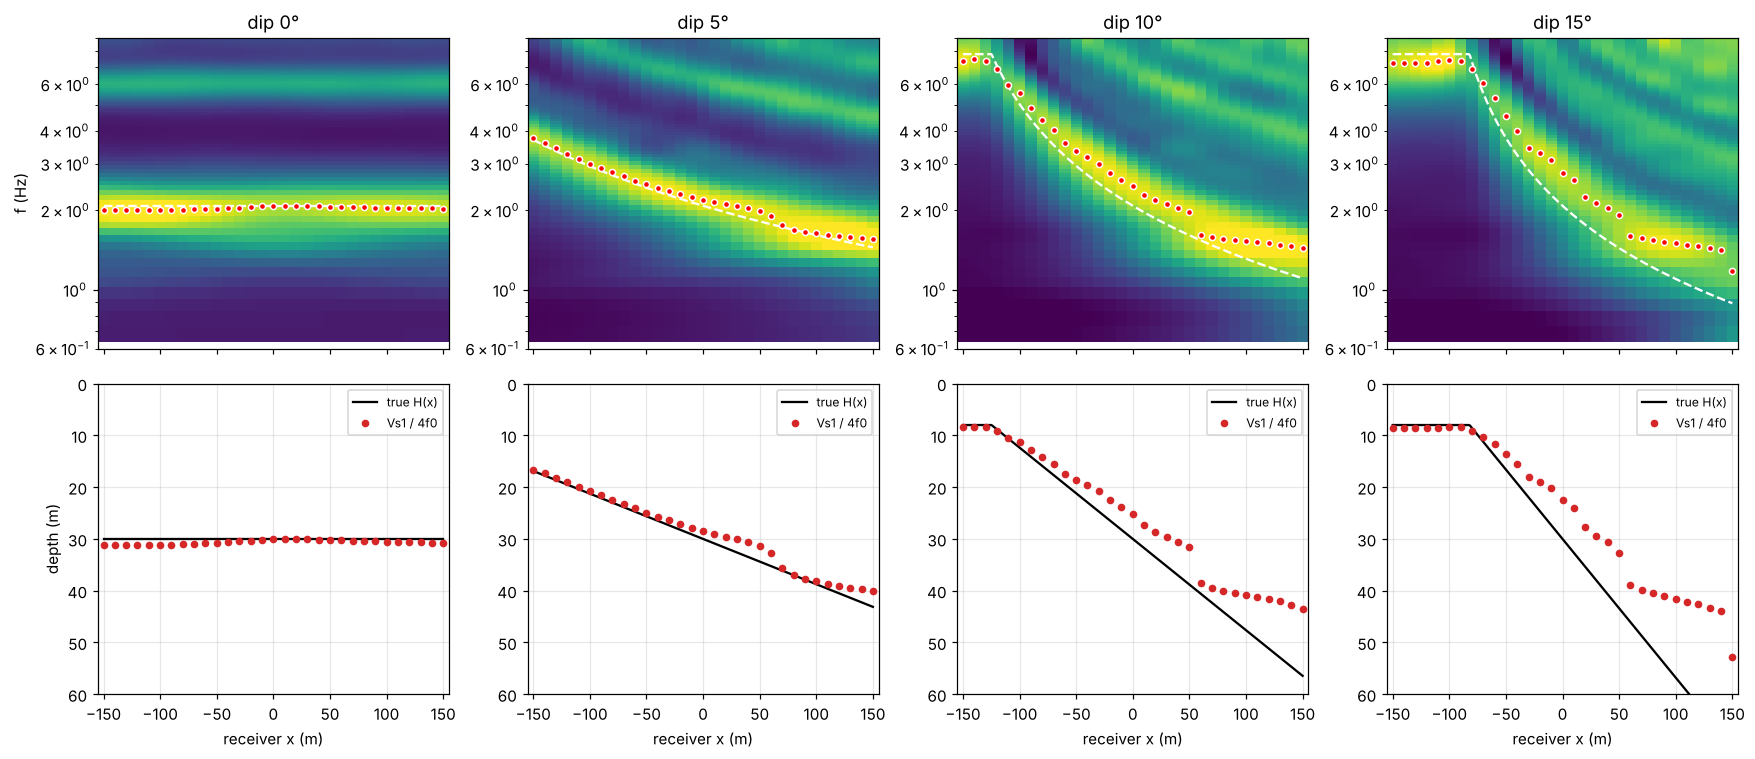

In [4]:
dips = [0.0, 5.0, 10.0, 15.0]
fig, ax = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
xx = np.linspace(-150, 150, 300)
summary = []
for k, d in enumerate(dips):
    r, md = run(dip=d), H.Model(dip=d)
    sel = (r["f"] >= 0.6) & (r["f"] <= 9)
    ax[0, k].pcolormesh(r["rec_x"], r["f"][sel], r["R"][sel], shading="nearest", vmin=1, vmax=np.percentile(r["R"][sel], 99))
    ax[0, k].plot(xx, md.f0_1d(xx), "w--", lw=1.5); ax[0, k].plot(r["rec_x"], r["f0"], "o", mfc="r", mec="w", ms=4)
    ax[0, k].set(yscale="log", ylim=(0.6, 9), title=f"dip {d:.0f}°"); ax[0, k].grid(False)
    ok = (md.f0_1d(r["rec_x"]) > 0.8) & (md.f0_1d(r["rec_x"]) < 8)
    ax[1, k].plot(xx, md.thickness(xx), "k", label="true H(x)")
    ax[1, k].plot(r["rec_x"][ok], md.vs1 / (4 * r["f0"][ok]), "o", color="C3", ms=4, label="Vs1 / 4f0")
    ax[1, k].set(ylim=(60, 0), xlabel="receiver x (m)"); ax[1, k].legend(fontsize=8)
    eH = 100 * (md.vs1 / (4 * r["f0"][ok]) / md.thickness(r["rec_x"][ok]) - 1)
    thick = r["rec_x"][ok] > 0
    summary.append((d, np.mean(eH), np.max(np.abs(eH)), np.mean(eH[thick]), np.mean(eH[~thick])))
ax[0, 0].set_ylabel("f (Hz)"); ax[1, 0].set_ylabel("depth (m)")
plt.tight_layout()
print(" dip   mean H error   max |H error|   thick side (x>0)   thin side (x<0)")
for d, a, b, c, e in summary:
    print(f" {d:3.0f}°     {a:+6.1f} %        {b:5.1f} %          {c:+6.1f} %          {e:+6.1f} %")

**Check against a finer grid** (dx = 2.5 m, 10° dip): the picks should not depend on the grid.

In [5]:
t0 = time.time()
rf = H.run_profile(H.Model(dip=10.0), H.default_grid(2.5), T=60.0)
rc = run(dip=10.0)
print(f"dx = 2.5 m run: {time.time() - t0:.0f} s; f0 difference from dx = 5 m: median {100 * np.median(np.abs(rf['f0'] / rc['f0'] - 1)):.1f} %")

dx = 2.5 m run: 135 s; f0 difference from dx = 5 m: median 3.2 %


## 4. Impedance contrast
Flat layer (H = 30 m), rock speed varied. The 1D theory says the peak height grows with the contrast (up to the damping limit) while $f_0$ stays at $V_{s1}/4H$.

 contrast   f0 FD (median)   f0 1D    peak FD   peak 1D
    2.6        2.06 Hz       2.10     2.02      2.32
    3.8        2.03 Hz       2.09     2.89      3.33
    5.1        2.04 Hz       2.09     3.71      4.25
    7.7        2.02 Hz       2.09     5.27      5.89
   10.2        2.11 Hz       2.08     6.43      7.29


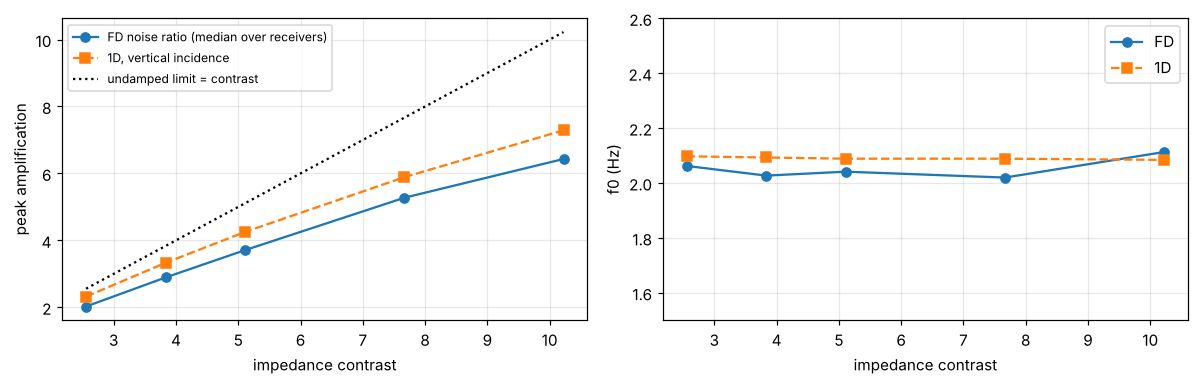

In [6]:
vs2s = [500.0, 750.0, 1000.0, 1500.0, 2000.0]
rows = []
for v in vs2s:
    r, mv = run(dip=0.0, vs2=v), H.Model(dip=0.0, vs2=v)
    rows.append((mv.contrast, np.median(r["f0"]), np.median(r["A0"]), mv.transfer_1d(ff)[ff < 4].max(),
                 ff[ff < 4][np.argmax(mv.transfer_1d(ff)[ff < 4])]))
rows = np.array(rows)
print(" contrast   f0 FD (median)   f0 1D    peak FD   peak 1D")
for c, f0, A, A1, f1 in rows:
    print(f"  {c:5.1f}       {f0:5.2f} Hz      {f1:5.2f}    {A:5.2f}     {A1:5.2f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(rows[:, 0], rows[:, 2], "o-", label="FD noise ratio (median over receivers)")
ax[0].plot(rows[:, 0], rows[:, 3], "s--", label="1D, vertical incidence")
ax[0].plot(rows[:, 0], rows[:, 0], "k:", label="undamped limit = contrast")
ax[0].set(xlabel="impedance contrast", ylabel="peak amplification"); ax[0].legend(fontsize=8)
ax[1].plot(rows[:, 0], rows[:, 1], "o-", label="FD"); ax[1].plot(rows[:, 0], rows[:, 4], "s--", label="1D")
ax[1].set(xlabel="impedance contrast", ylabel="f0 (Hz)", ylim=(1.5, 2.6)); ax[1].legend()
plt.tight_layout()

**Contrast and dip together.** Does the 2D error depend on the contrast? A strong contrast traps the waves in the layer, so they can travel sideways along it; a weak contrast lets them leak down into the rock, so each column behaves more like its own 1D site.

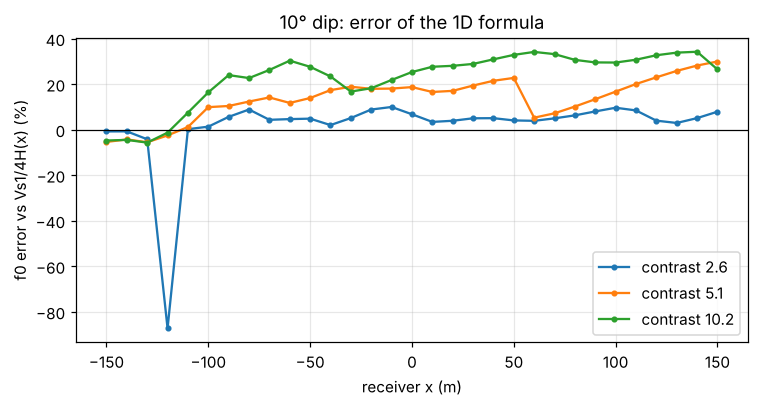

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for v in (500.0, 1000.0, 2000.0):
    r, mv = run(dip=10.0, vs2=v), H.Model(dip=10.0, vs2=v)
    ok = (mv.f0_1d(r["rec_x"]) > 0.8) & (mv.f0_1d(r["rec_x"]) < 8)
    ax.plot(r["rec_x"][ok], 100 * (r["f0"][ok] / mv.f0_1d(r["rec_x"][ok]) - 1), "o-", ms=3, label=f"contrast {mv.contrast:.1f}")
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="receiver x (m)", ylabel="f0 error vs Vs1/4H(x) (%)", title="10° dip: error of the 1D formula"); ax.legend()
plt.tight_layout()

## 5. Surface-wave noise
Real noise also contains surface waves arriving from the sides. Here 12 extra sources sit at 2 m depth, 20-140 m beyond the line ends. The soft layer guides their energy as Love waves. The ratio becomes station-dependent: the peak near $f_0$ broadens or shifts, and receivers close to a surface source are dominated by its near field at high frequency. The body-wave-only runs above are the clean case; this is why field practice averages long records and many windows.

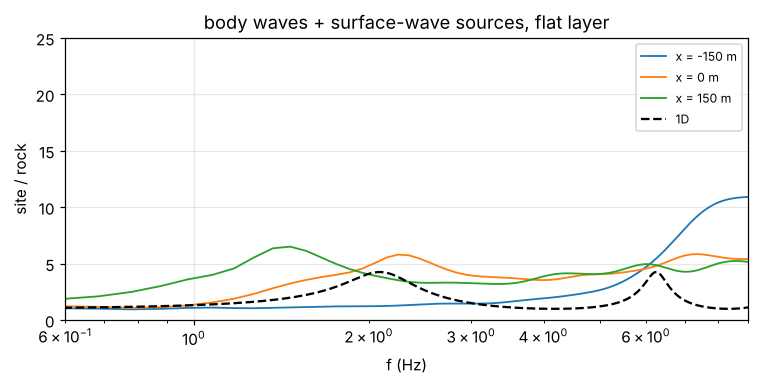

In [8]:
src12 = H.noise_sources(n_surface=12)
s = H.simulate_noise(m, GRID, T=T, src=src12); rr = H.simulate_noise(m, GRID, T=T, src=src12, homogeneous=True)
f, R = H.spectral_ratio(s, rr)
fig, ax = plt.subplots(figsize=(7, 3.6))
for j in (0, 15, 30):
    ax.plot(f, R[:, j], lw=1.2, label=f"x = {s['rec_x'][j]:.0f} m")
ax.plot(ff, m.transfer_1d(ff), "k--", label="1D")
ax.set(xscale="log", xlim=(0.6, 9), ylim=(0, 25), xlabel="f (Hz)", ylabel="site / rock", title="body waves + surface-wave sources, flat layer")
ax.legend(fontsize=8); plt.tight_layout()

## Findings
* **Flat layer:** with noise from all directions, $f_0$ matches $V_{s1}/4H$ within 4% at every receiver; the peak height is about 12% below the 1D vertical-incidence value (oblique waves, lateral energy flow).
* **Dip makes the 1D conversion underestimate depth.** $f_0$ varies more smoothly along the line than $V_{s1}/4H(x)$, so $H = V_{s1}/4f_0$ comes out too shallow: about 4% on average at 5°, 11% at 10° and 15% at 15°, and up to 25-35% under the thick side. The resonance couples laterally, which a 1D conversion ignores.
* **Stronger contrast makes this worse, not better.** At 10° dip the $f_0$ error is about 5% for a contrast of 2.6 but 20-35% for a contrast of 10: a strong contrast traps the energy, so it spreads along the layer. (One pick at contrast 2.6 jumped to a different peak, -87%.) A strong contrast gives a taller, sharper peak, so it is easy to pick but harder to interpret with 1D theory.
* **Surface-wave noise** from nearby lateral sources makes the ratio station-dependent and less reliable.
* **Limits:** SH/scalar only (no true H/V, no Rayleigh waves), 2D (out-of-plane uniform), linear elastic with simple viscous damping, two layers.